# CS3807 – Deep Learning Laboratory · Experiments 8 & 9
## Effect of Attention Type and Attention Position in a Pretrained ResNet50
**Dataset:** TensorFlow Flowers (5 classes) · **Backbone:** ImageNet-pretrained ResNet50 (only backbone used)

**How to use**
1. `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
2. All settings are in the *Configuration* cell. Set `QUICK_TEST = True` first to check that everything runs (1+1 epochs per model).
3. `RUN_TIERS` controls how many experiments are trained: `minimum` (Sec. 35 mandatory set), `main` (Experiments 1–5 of the manual), `extra` (ECA, CBAM, Coordinate Attention).
4. Every finished experiment is saved to `/content/lab_outputs` (JSON + weights). If the session restarts, re-running skips finished runs.

**Protocol (Sec. 34):** same split, seed, preprocessing, augmentation, optimizer, batch size, epochs, LR schedule and fine-tuning for *every* model. Only the attention factor changes.

Section numbers in comments refer to the lab manual.

In [ ]:
# GPU check
import tensorflow as tf
print('TensorFlow', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('WARNING: no GPU found. Use Runtime > Change runtime type > T4 GPU.')

TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Configuration ---------------------------------------------------------------
import os, gc, json, time, math, random, pathlib, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED        = 42
QUICK_TEST  = False            # True -> 1 + 1 epochs per model, just to test the pipeline
E1, E2      = (1, 1) if QUICK_TEST else (5, 5)   # epochs: phase 1 (frozen backbone), phase 2 (fine-tune conv5)
BATCH       = 32
LR_HEAD     = 1e-3             # Sec. 20: new layers
LR_FT       = 1e-4             # Sec. 20: fine-tuning (10^-5 .. 10^-4)
DROPOUT     = 0.3
REDUCTION   = 16               # Sec. 9: default reduction ratio
GATE_BIAS   = 2.0              # initial bias of every sigmoid gate (sigmoid(2)=0.88) so that a freshly
                               # inserted gate does not shrink the pretrained features. Same for ALL
                               # attention models. Set 0.0 for the plain textbook initialisation.
WEIGHTS     = 'imagenet'
RUN_TIERS   = ['minimum', 'main', 'extra']
ATTN_MODEL  = 'A3_chan_spatial_P3'      # attention model used for confusion matrix / Grad-CAM comparison

OUT = pathlib.Path('/content/lab_outputs'); (OUT / 'weights').mkdir(parents=True, exist_ok=True)

# Optional: keep results on Google Drive so they survive a runtime reset
# from google.colab import drive; drive.mount('/content/drive')
# OUT = pathlib.Path('/content/drive/MyDrive/cs3807_attention'); (OUT/'weights').mkdir(parents=True, exist_ok=True)

def set_seeds(s=SEED):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    keras.utils.set_random_seed(s)
set_seeds()

## 1. Dataset (Sec. 3)
The TensorFlow Flowers images are loaded once, resized to 224×224×3 and split **70 : 15 : 15** (stratified, fixed seed). The split indices are saved, so every ablation uses exactly the same train / validation / test samples. ResNet50 preprocessing and augmentation are part of the model (augmentation layers are active only during training).

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Total images: (3670, 224, 224, 3)  classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


,train,val,test
daisy,443,95,95
dandelion,629,134,135
roses,449,96,96
sunflowers,489,105,105
tulips,559,120,120
TOTAL,2569,550,551


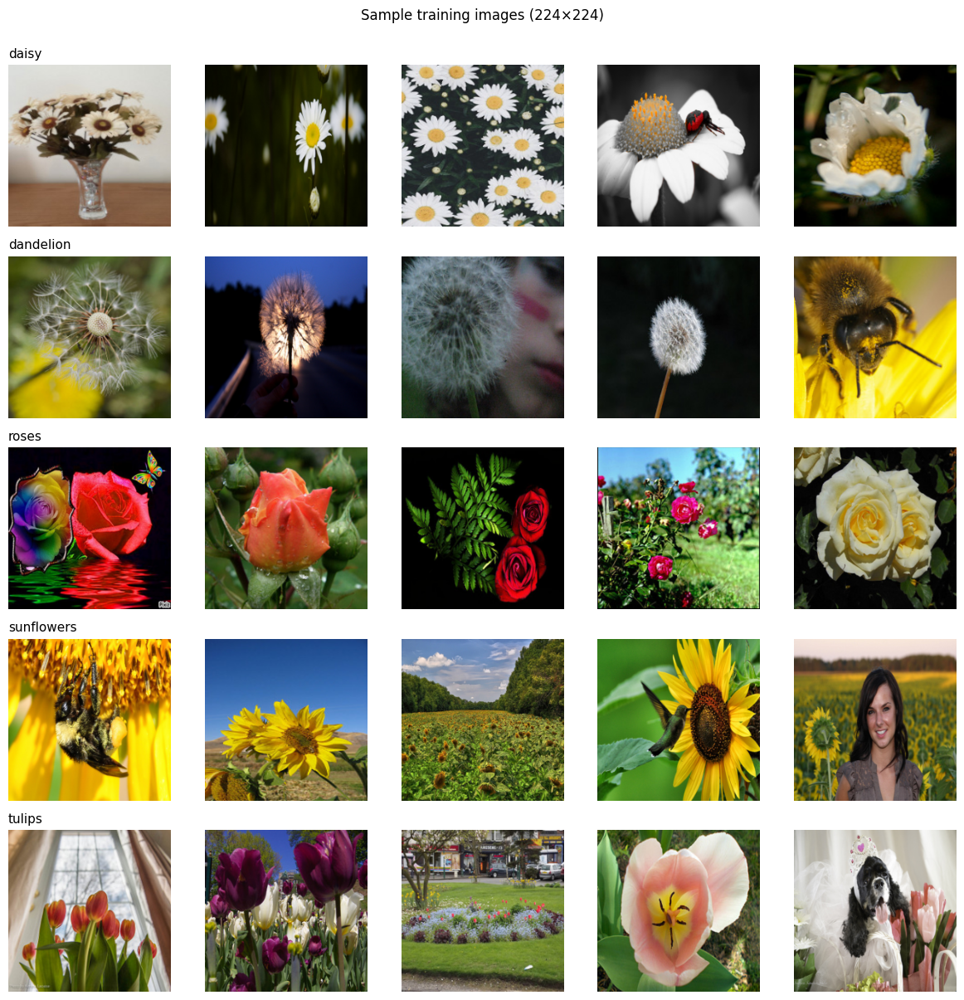

In [ ]:
from PIL import Image

# Same TensorFlow Flowers dataset (3,670 images, 5 classes), downloaded directly (no tensorflow_datasets needed)
URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
fpath = keras.utils.get_file('flower_photos.tgz', origin=URL, extract=True)
base = pathlib.Path(fpath).parent
root = next(p.parent for p in base.rglob('daisy') if p.is_dir())
CLASS_NAMES = sorted(d.name for d in root.iterdir() if d.is_dir())      # daisy, dandelion, roses, sunflowers, tulips
NUM_CLASSES = len(CLASS_NAMES)

files, y_all = [], []
for ci, cn in enumerate(CLASS_NAMES):
    fs = sorted((root / cn).glob('*.jpg'))
    files += fs; y_all += [ci] * len(fs)
y_all = np.array(y_all)
X_all = np.stack([np.asarray(Image.open(f).convert('RGB').resize((224, 224), Image.BILINEAR)) for f in files]).astype('uint8')
print('Total images:', X_all.shape, ' classes:', CLASS_NAMES)

idx = np.arange(len(y_all))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=SEED)
np.savez(OUT / 'split_indices.npz', train=tr_idx, val=va_idx, test=te_idx)

Xtr, ytr = X_all[tr_idx], y_all[tr_idx]
Xva, yva = X_all[va_idx], y_all[va_idx]
Xte, yte = X_all[te_idx], y_all[te_idx]
del X_all; gc.collect()
Ytr, Yva = keras.utils.to_categorical(ytr, NUM_CLASSES), keras.utils.to_categorical(yva, NUM_CLASSES)

split_df = pd.DataFrame({'train': np.bincount(ytr), 'val': np.bincount(yva), 'test': np.bincount(yte)}, index=CLASS_NAMES)
split_df.loc['TOTAL'] = split_df.sum()
display(split_df)

# Required visualisation 1: sample images from all five classes
fig, axs = plt.subplots(NUM_CLASSES, 5, figsize=(12, 2.4 * NUM_CLASSES))
rng = np.random.RandomState(0)
for c in range(NUM_CLASSES):
    pick = rng.choice(np.where(ytr == c)[0], 5, replace=False)
    for j, k in enumerate(pick):
        axs[c, j].imshow(Xtr[k]); axs[c, j].axis('off')
    axs[c, 0].set_title(CLASS_NAMES[c], loc='left', fontsize=11)
plt.suptitle('Sample training images (224×224)', y=1.0); plt.tight_layout(); plt.show()

## 2. Attention modules (Sec. 9 – 12, 19)
All modules take a feature tensor `F ∈ R^{H×W×C}` and return a tensor of the **same shape** (Sec. 13).

| token | module | notes |
|---|---|---|
| `c` | Channel attention | GAP → W1 (ReLU) → W2 (sigmoid), r = 16. This is the SE formulation, so "Channel / SE" in the tables is the same model |
| `s` | Spatial attention | mean & max over channels → Conv k×k → sigmoid |
| `sa` | Self-attention | Q, K, V 1×1 convs, softmax(QKᵀ/√d)V, residual `F + γ·Y` (γ learnable, init 0) |
| `eca` | ECA | GAP → 1-D conv across channels (adaptive kernel) → sigmoid |
| `cbam_c` | CBAM channel part | shared MLP on GAP **and** GMP descriptors; CBAM = `cbam_c` then `s` (k = 7) |
| `coord` | Coordinate attention | directional pooling along H and W, shared 1×1 conv, two sigmoid gates |

Each module has `return_map=True` so the **internal attention weights** can be extracted for visualisation (Sec. 28).

In [ ]:
def gate_init():
    return keras.initializers.Constant(GATE_BIAS)

class ChannelAttention(layers.Layer):          # Sec. 9 (SE-style)
    def __init__(self, ratio=REDUCTION, **kw):
        super().__init__(**kw); self.ratio = ratio
    def build(self, input_shape):
        C = int(input_shape[-1])
        self.fc1 = layers.Dense(max(C // self.ratio, 4), activation='relu')
        self.fc2 = layers.Dense(C, activation='sigmoid', bias_initializer=gate_init())
    def call(self, x, training=None, return_map=False):
        z = tf.reduce_mean(x, axis=[1, 2])                 # (B, C) channel descriptor
        m = self.fc2(self.fc1(z))                          # (B, C) Mc(F)
        out = x * m[:, None, None, :]
        return (out, m) if return_map else out

class SpatialAttention(layers.Layer):          # Sec. 10
    def __init__(self, kernel_size=7, **kw):
        super().__init__(**kw); self.k = kernel_size
        self.conv = layers.Conv2D(1, kernel_size, padding='same', activation='sigmoid',
                                  bias_initializer=gate_init())
    def call(self, x, training=None, return_map=False):
        avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        mx  = tf.reduce_max(x, axis=-1, keepdims=True)
        m = self.conv(tf.concat([avg, mx], axis=-1))       # (B, H, W, 1) Ms(F)
        out = x * m
        return (out, m) if return_map else out

class SelfAttention(layers.Layer):             # Sec. 12
    def __init__(self, qk_ratio=8, v_ratio=2, **kw):
        super().__init__(**kw); self.qk_ratio, self.v_ratio = qk_ratio, v_ratio
    def build(self, input_shape):
        C = int(input_shape[-1])
        self.d  = max(C // self.qk_ratio, 8)
        self.dv = max(C // self.v_ratio, 8)
        self.q = layers.Conv2D(self.d, 1, use_bias=False)
        self.k = layers.Conv2D(self.d, 1, use_bias=False)
        self.v = layers.Conv2D(self.dv, 1, use_bias=False)
        self.o = layers.Conv2D(C, 1, use_bias=False)
        self.gamma = self.add_weight(name='gamma', shape=(), initializer='zeros', trainable=True)
    def call(self, x, training=None, return_map=False):
        H, W = int(x.shape[1]), int(x.shape[2]); N = H * W
        q = tf.reshape(self.q(x), [-1, N, self.d])
        k = tf.reshape(self.k(x), [-1, N, self.d])
        v = tf.reshape(self.v(x), [-1, N, self.dv])
        A = tf.nn.softmax(tf.matmul(q, k, transpose_b=True) / math.sqrt(self.d), axis=-1)   # (B, N, N)
        y = self.o(tf.reshape(tf.matmul(A, v), [-1, H, W, self.dv]))
        out = x + self.gamma * y
        if not return_map:
            return out
        mean_map   = tf.reduce_mean(A, axis=1)                        # how much each location is attended to
        center_map = A[:, (H // 2) * W + W // 2, :]                   # attention of the centre query
        m = tf.reshape(tf.stack([mean_map, center_map], axis=-1), [-1, H, W, 2])
        return out, m

class ECA(layers.Layer):                       # Sec. 19
    def __init__(self, gamma=2, b=1, **kw):
        super().__init__(**kw); self.g, self.b = gamma, b
    def build(self, input_shape):
        C = int(input_shape[-1])
        k = int(abs((math.log2(C) + self.b) / self.g)); k = k if k % 2 else k + 1
        self.conv = layers.Conv1D(1, k, padding='same', activation='sigmoid', bias_initializer=gate_init())
    def call(self, x, training=None, return_map=False):
        z = tf.reduce_mean(x, axis=[1, 2])                            # (B, C)
        m = self.conv(z[:, :, None])[:, :, 0]                         # (B, C)
        out = x * m[:, None, None, :]
        return (out, m) if return_map else out

class CBAMChannel(layers.Layer):               # channel half of CBAM (avg + max, shared MLP)
    def __init__(self, ratio=REDUCTION, **kw):
        super().__init__(**kw); self.ratio = ratio
    def build(self, input_shape):
        C = int(input_shape[-1])
        self.fc1 = layers.Dense(max(C // self.ratio, 4), activation='relu')
        self.fc2 = layers.Dense(C)
    def call(self, x, training=None, return_map=False):
        a = self.fc2(self.fc1(tf.reduce_mean(x, axis=[1, 2])))
        b = self.fc2(self.fc1(tf.reduce_max(x, axis=[1, 2])))
        m = tf.sigmoid(a + b + GATE_BIAS)
        out = x * m[:, None, None, :]
        return (out, m) if return_map else out

class CoordAtt(layers.Layer):                  # Hou et al., CVPR 2021
    def __init__(self, reduction=32, **kw):
        super().__init__(**kw); self.reduction = reduction
    def build(self, input_shape):
        C = int(input_shape[-1]); mip = max(8, C // self.reduction)
        self.conv1  = layers.Conv2D(mip, 1)
        self.bn     = layers.BatchNormalization()
        self.act    = layers.Activation('relu')
        self.conv_h = layers.Conv2D(C, 1, activation='sigmoid', bias_initializer=gate_init())
        self.conv_w = layers.Conv2D(C, 1, activation='sigmoid', bias_initializer=gate_init())
    def call(self, x, training=None, return_map=False):
        H, W = int(x.shape[1]), int(x.shape[2])
        x_h = tf.reduce_mean(x, axis=2, keepdims=True)                              # (B,H,1,C)
        x_w = tf.transpose(tf.reduce_mean(x, axis=1, keepdims=True), [0, 2, 1, 3])  # (B,W,1,C)
        y = self.act(self.bn(self.conv1(tf.concat([x_h, x_w], axis=1)), training=training))
        y_h, y_w = tf.split(y, [H, W], axis=1)
        a_h = self.conv_h(y_h)                                                      # (B,H,1,C)
        a_w = tf.transpose(self.conv_w(y_w), [0, 2, 1, 3])                          # (B,1,W,C)
        out = x * a_h * a_w
        if not return_map:
            return out
        return out, tf.reduce_mean(a_h * a_w, axis=-1, keepdims=True)               # (B,H,W,1)

def make_module(tok, kernel_size=7):
    return {'c': lambda: ChannelAttention(), 's': lambda: SpatialAttention(kernel_size),
            'sa': lambda: SelfAttention(), 'eca': lambda: ECA(),
            'cbam_c': lambda: CBAMChannel(), 'coord': lambda: CoordAtt()}[tok]()

class AttnBlock(layers.Layer):
    # applies the modules in `seq` one after another, e.g. ['c','s'] = Channel -> Spatial
    def __init__(self, seq, kernel_size=7, **kw):
        super().__init__(**kw)
        self.seq = list(seq)
        self.mods = [make_module(t, kernel_size) for t in self.seq]
    def call(self, x, training=None):
        for m in self.mods:
            x = m(x, training=training)
        return x
    def explain(self, x):
        maps = {}
        for t, m in zip(self.seq, self.mods):
            x, maps[t] = m(x, training=False, return_map=True)
        return x, maps

## 3. Inserting attention into ResNet50 (Sec. 4, 7, 8, 13, 20)
ResNet50's layers are re-applied in order, and an attention block is placed after the chosen stage(s):

| position | location | feature size |
|---|---|---|
| P1 | after conv2_x | 56×56×256 |
| P2 | after conv3_x | 28×28×512 |
| P3 | after conv4_x | 14×14×1024 |
| P4 | after conv5_x | 7×7×2048 |

`Input → [Aug] → ResNet preprocessing → stem → conv2_x → (P1) → conv3_x → (P2) → conv4_x → (P3) → conv5_x → (P4) → GAP → Dropout → Dense(5) → Softmax`.
The pretrained layers are shared objects, so the weights are exactly the ImageNet weights.

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

STAGES = {1: (2, 3), 2: (3, 4), 3: (4, 6), 4: (5, 3)}      # position -> (conv stage, number of blocks)

def resnet_block(L, x, stage, b):
    p = f'conv{stage}_block{b}'
    s = x
    if b == 1:
        s = L(p + '_0_bn')(L(p + '_0_conv')(x))
    y = L(p + '_1_relu')(L(p + '_1_bn')(L(p + '_1_conv')(x)))
    y = L(p + '_2_relu')(L(p + '_2_bn')(L(p + '_2_conv')(y)))
    y = L(p + '_3_bn')(L(p + '_3_conv')(y))
    return L(p + '_out')(L(p + '_add')([s, y]))

def augmentation():
    # identical for every model (Sec. 3.1); active only when training=True
    return keras.Sequential([
        layers.RandomFlip('horizontal', seed=SEED),
        layers.RandomRotation(0.05, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
        layers.RandomTranslation(0.1, 0.1, seed=SEED),
        layers.RandomContrast(0.1, seed=SEED)], name='augment')

def build_model(attn_cfg, kernel_size=7):
    # attn_cfg: {position(1..4): [tokens]}  e.g. {3: ['c','s']}
    set_seeds()
    base = keras.applications.ResNet50(weights=WEIGHTS, include_top=False, input_shape=(224, 224, 3))
    L = base.get_layer
    inp = keras.Input((224, 224, 3), name='image')
    x = layers.Lambda(lambda t: tf.cast(t, tf.float32), name='to_float')(inp)
    x = augmentation()(x)
    x = layers.Lambda(preprocess_input, name='resnet_preprocess')(x)
    for n in ['conv1_pad', 'conv1_conv', 'conv1_bn', 'conv1_relu', 'pool1_pad', 'pool1_pool']:
        x = L(n)(x)
    blocks, feats, shapes = {}, [], {}
    for pos, (stage, nb) in STAGES.items():
        for b in range(1, nb + 1):
            x = resnet_block(L, x, stage, b)
        feats.append(x)                                       # feature at P<pos> BEFORE attention
        if pos in attn_cfg:
            blk = AttnBlock(attn_cfg[pos], kernel_size, name=f'attn_P{pos}')
            before = tuple(x.shape[1:]); x = blk(x); after = tuple(x.shape[1:])
            assert before == after, 'attention must not change the tensor shape'
            blocks[pos] = blk; shapes[pos] = (before, after)
    feat = x
    g = layers.GlobalAveragePooling2D(name='gap')(feat)
    g = layers.Dropout(DROPOUT, name='dropout')(g)
    logits = layers.Dense(NUM_CLASSES, name='logits')(g)
    probs  = layers.Softmax(name='probs')(logits)
    model     = keras.Model(inp, probs, name='resnet50_attn')
    cam_model = keras.Model(inp, [feat, logits, probs])       # shares all layers (Grad-CAM)
    probe     = keras.Model(inp, feats)                       # features at P1..P4 before attention
    return model, dict(base=base, blocks=blocks, shapes=shapes, cam_model=cam_model, probe=probe)

def set_phase(parts, phase):
    # phase 1: backbone frozen; phase 2: conv5_x conv layers unfrozen (BatchNorm kept frozen)
    for l in parts['base'].layers:
        l.trainable = False
    if phase == 2:
        for l in parts['base'].layers:
            if l.name.startswith('conv5_') and not isinstance(l, layers.BatchNormalization):
                l.trainable = True

def n_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))

In [ ]:
# Sanity check 1: our re-assembled graph == the original pretrained ResNet50 (baseline, no attention)
model, parts = build_model({})
xb = Xtr[:4].astype('float32')
ref  = parts['base'](preprocess_input(xb.copy()), training=False).numpy()
ours = parts['cam_model'](xb, training=False)[0].numpy()
print('Max |difference| to original ResNet50 conv5 output:', float(np.abs(ref - ours).max()))

# Sanity check 2 / Sec. 13 + 38(1): feature dimensions immediately before and after each attention block
rows = []
for name, cfg in {'Channel+Spatial @P2': {2: ['c', 's']}, 'Channel+Spatial @P3': {3: ['c', 's']},
                  'Channel+Spatial @P4': {4: ['c', 's']}, 'Self-Attention @P3': {3: ['sa']},
                  'Self-Attention @P4': {4: ['sa']}}.items():
    m, p = build_model(cfg)
    for pos, (b, a) in p['shapes'].items():
        rows.append(dict(model=name, position=f'P{pos}', before=str(b), after=str(a),
                         attention_params=p['blocks'][pos].count_params()))
    keras.backend.clear_session(); gc.collect()
display(pd.DataFrame(rows))
del model, parts; keras.backend.clear_session(); gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Max |difference| to original ResNet50 conv5 output: 0.0


,model,position,before,after,attention_params
0,Channel+Spatial @P2,P2,"(28, 28, 512)","(28, 28, 512)",33411
1,Channel+Spatial @P3,P3,"(14, 14, 1024)","(14, 14, 1024)",132259
2,Channel+Spatial @P4,P4,"(7, 7, 2048)","(7, 7, 2048)",526563
3,Self-Attention @P3,P3,"(14, 14, 1024)","(14, 14, 1024)",1310721
4,Self-Attention @P4,P4,"(7, 7, 2048)","(7, 7, 2048)",5242881


0

## 4. Training and evaluation (Sec. 20 – 22)
Two-phase transfer learning, identical for every model:
1. **Phase 1** – backbone frozen, train attention + classifier, `Adam(1e-3)`, `E1` epochs.
2. **Phase 2** – unfreeze conv5_x (BatchNorm frozen), `Adam(1e-4)`, `E2` epochs.

Loss = categorical cross-entropy. Metrics: accuracy, macro precision / recall / F1, trainable and total parameters, average inference time per image (batched, GPU, after warm-up).

In [ ]:
def predict_timed(model, X, bs=32):
    fn = tf.function(lambda t: model(t, training=False), reduce_retracing=True)
    fn(tf.constant(X[:bs], dtype=tf.float32)).numpy()                      # warm-up (not timed)
    probs, total = [], 0.0
    for i in range(0, len(X), bs):
        xb = tf.constant(X[i:i + bs], dtype=tf.float32)
        t0 = time.perf_counter(); p = fn(xb).numpy(); total += time.perf_counter() - t0
        probs.append(p)
    return np.concatenate(probs), 1000.0 * total / len(X)                 # ms / image

def run_experiment(name, cfg):
    jpath = OUT / f'{name}.json'
    if jpath.exists():
        print(f'[skip] {name} (already finished)'); return json.load(open(jpath))
    print(f'\n=== {name} | attention = {cfg["attn"]} | kernel = {cfg.get("kernel", 7)} ===')
    t_start = time.time()
    model, parts = build_model(cfg['attn'], cfg.get('kernel', 7))
    loss = keras.losses.CategoricalCrossentropy()

    set_phase(parts, 1)
    model.compile(keras.optimizers.Adam(LR_HEAD), loss=loss, metrics=['accuracy'])
    trainable_p1 = n_params(model.trainable_weights)
    h1 = model.fit(Xtr, Ytr, validation_data=(Xva, Yva), epochs=E1, batch_size=BATCH, verbose=2)

    set_phase(parts, 2)
    model.compile(keras.optimizers.Adam(LR_FT), loss=loss, metrics=['accuracy'])
    trainable_p2 = n_params(model.trainable_weights)
    h2 = model.fit(Xtr, Ytr, validation_data=(Xva, Yva), epochs=E2, batch_size=BATCH, verbose=2)

    hist = {k: [float(v) for v in h1.history[k] + h2.history[k]] for k in h1.history}
    probs, ms = predict_timed(model, Xte)
    yp = probs.argmax(1)
    pr, rc, f1, _ = precision_recall_fscore_support(yte, yp, average='macro', zero_division=0)
    res = dict(name=name, attn=str(cfg['attn']), kernel=cfg.get('kernel', 7),
               test_acc=float(accuracy_score(yte, yp)), precision=float(pr), recall=float(rc), f1=float(f1),
               train_acc=hist['accuracy'][-1], val_acc=hist['val_accuracy'][-1],
               train_loss=hist['loss'][-1], val_loss=hist['val_loss'][-1],
               trainable_params=trainable_p2, trainable_params_phase1=trainable_p1,
               total_params=int(model.count_params()),
               attn_params=int(sum(b.count_params() for b in parts['blocks'].values())),
               inference_ms=float(ms), history=hist, phase1_epochs=E1,
               y_pred=[int(v) for v in yp], seconds=time.time() - t_start,
               shapes={f'P{p}': [list(a), list(b)] for p, (a, b) in parts['shapes'].items()})
    model.save_weights(OUT / 'weights' / f'{name}.weights.h5')
    json.dump(res, open(jpath, 'w'))
    print(f'-> test acc {res["test_acc"]:.4f} | macro-F1 {res["f1"]:.4f} | params {res["total_params"]:,} '
          f'| {res["inference_ms"]:.2f} ms/img | {res["seconds"]/60:.1f} min')
    del model, parts; keras.backend.clear_session(); gc.collect()
    return res

## 5. Experiment registry (Sec. 14 – 19, 35)
Token key: `c` channel · `s` spatial · `sa` self-attention · `eca` · `cbam_c`+`s` = CBAM · `coord`.
Aliases (no re-training needed): **B3 = A3** (Channel→Spatial @P3), **spatial kernel 7×7 = A3**, **Channel/SE = A1**.

In [ ]:
CS = ['c', 's']
EXPERIMENTS = {
 # ---- minimum mandatory set (Sec. 35)
 'A0_baseline':          dict(tier='minimum', attn={},                 label='Baseline',            pos='–'),
 'A1_channel_P3':        dict(tier='minimum', attn={3: ['c']},         label='Channel (SE)',        pos='P3'),
 'A2_spatial_P3':        dict(tier='minimum', attn={3: ['s']},         label='Spatial',             pos='P3'),
 'A3_chan_spatial_P3':   dict(tier='minimum', attn={3: CS},            label='Channel+Spatial',     pos='P3'),
 'A4_selfattn_P3':       dict(tier='minimum', attn={3: ['sa']},        label='Self-Attention',      pos='P3'),
 'B2_cs_P2':             dict(tier='minimum', attn={2: CS},            label='Channel+Spatial',     pos='P2'),
 'B4_cs_P4':             dict(tier='minimum', attn={4: CS},            label='Channel+Spatial',     pos='P4'),
 # ---- main experiments 1-5
 'A5_combined_P3':       dict(tier='main',    attn={3: ['c','s','sa']},label='Combined (C+S+SA)',   pos='P3'),
 'B1_cs_P1':             dict(tier='main',    attn={1: CS},            label='Channel+Spatial',     pos='P1'),
 'C1_cs_P3P4':           dict(tier='main',    attn={3: CS, 4: CS},     label='Channel+Spatial',     pos='P3+P4'),
 'C2_cs_P2P3P4':         dict(tier='main',    attn={2: CS, 3: CS, 4: CS}, label='Channel+Spatial',  pos='P2+P3+P4'),
 'D1_spatial_channel_P3':dict(tier='main',    attn={3: ['s','c']},     label='Spatial→Channel',     pos='P3'),
 'E1_cs_k3_P3':          dict(tier='main',    attn={3: CS}, kernel=3,  label='Ch+Sp (k=3)',         pos='P3'),
 'E2_cs_k5_P3':          dict(tier='main',    attn={3: CS}, kernel=5,  label='Ch+Sp (k=5)',         pos='P3'),
 # ---- additional mechanisms (Sec. 19, 36)
 'X1_ECA_P3':            dict(tier='extra',   attn={3: ['eca']},       label='ECA',                 pos='P3'),
 'X2_CBAM_P3':           dict(tier='extra',   attn={3: ['cbam_c','s']},label='CBAM',                pos='P3'),
 'X3_CoordAtt_P3':       dict(tier='extra',   attn={3: ['coord']},     label='Coordinate Att.',     pos='P3'),
}
ALIAS = {'B3_cs_P3': 'A3_chan_spatial_P3', 'E3_cs_k7_P3': 'A3_chan_spatial_P3', 'X0_SE_P3': 'A1_channel_P3'}
print({t: [n for n, c in EXPERIMENTS.items() if c['tier'] == t] for t in ['minimum', 'main', 'extra']})

{'minimum': ['A0_baseline', 'A1_channel_P3', 'A2_spatial_P3', 'A3_chan_spatial_P3', 'A4_selfattn_P3', 'B2_cs_P2', 'B4_cs_P4'], 'main': ['A5_combined_P3', 'B1_cs_P1', 'C1_cs_P3P4', 'C2_cs_P2P3P4', 'D1_spatial_channel_P3', 'E1_cs_k3_P3', 'E2_cs_k5_P3'], 'extra': ['X1_ECA_P3', 'X2_CBAM_P3', 'X3_CoordAtt_P3']}


In [ ]:
RES = {}
todo = [n for n, c in EXPERIMENTS.items() if c['tier'] in RUN_TIERS]
print(f'Training {len(todo)} models x ({E1}+{E2}) epochs')
for n in todo:
    RES[n] = run_experiment(n, EXPERIMENTS[n])

Training 17 models x (5+5) epochs

=== A0_baseline | attention = {} | kernel = 7 ===
Epoch 1/5
81/81 - 27s - 335ms/step - accuracy: 0.6757 - loss: 0.8804 - val_accuracy: 0.8455 - val_loss: 0.4395
Epoch 2/5
81/81 - 13s - 162ms/step - accuracy: 0.8365 - loss: 0.4476 - val_accuracy: 0.8673 - val_loss: 0.3442
Epoch 3/5
81/81 - 13s - 166ms/step - accuracy: 0.8743 - loss: 0.3528 - val_accuracy: 0.8709 - val_loss: 0.3268
Epoch 4/5
81/81 - 14s - 172ms/step - accuracy: 0.8863 - loss: 0.3123 - val_accuracy: 0.8800 - val_loss: 0.3233
Epoch 5/5
81/81 - 14s - 175ms/step - accuracy: 0.9007 - loss: 0.2785 - val_accuracy: 0.8927 - val_loss: 0.3139
Epoch 1/5
81/81 - 29s - 363ms/step - accuracy: 0.8945 - loss: 0.2961 - val_accuracy: 0.9218 - val_loss: 0.2389
Epoch 2/5
81/81 - 17s - 213ms/step - accuracy: 0.9482 - loss: 0.1478 - val_accuracy: 0.9091 - val_loss: 0.2969
Epoch 3/5
81/81 - 17s - 212ms/step - accuracy: 0.9521 - loss: 0.1398 - val_accuracy: 0.8891 - val_loss: 0.3594
Epoch 4/5
81/81 - 17s - 210

## 6. Quantitative and complexity results (Sec. 22, 23, 33)

In [ ]:
def load_results():
    out = {}
    for n in EXPERIMENTS:
        p = OUT / f'{n}.json'
        if p.exists(): out[n] = json.load(open(p))
    return out
RES = load_results()
have = lambda n: n in RES

def row(n, label=None, pos=None):
    r = RES[n]; c = EXPERIMENTS[n]
    return {'Model': label or c['label'], 'Position': pos or c['pos'],
            'Accuracy': r['test_acc'], 'Precision': r['precision'], 'Recall': r['recall'], 'F1': r['f1'],
            'Trainable params': r['trainable_params'], 'Total params': r['total_params'],
            'Attn params': r['attn_params'], 'Inference (ms/img)': r['inference_ms']}

fmt = {'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}',
       'Trainable params': '{:,}', 'Total params': '{:,}', 'Attn params': '{:,}', 'Inference (ms/img)': '{:.3f}'}

# Sec. 23: required main result table
main_rows = [('A0_baseline', 'Baseline', '–'), ('A1_channel_P3', 'Channel Attention', 'P3'),
             ('A2_spatial_P3', 'Spatial Attention', 'P3'), ('B2_cs_P2', 'Channel+Spatial', 'P2'),
             ('A3_chan_spatial_P3', 'Channel+Spatial', 'P3'), ('B4_cs_P4', 'Channel+Spatial', 'P4'),
             ('A4_selfattn_P3', 'Self-Attention', 'P3'), ('X1_ECA_P3', 'Additional Attention-1 (ECA)', 'P3'),
             ('X2_CBAM_P3', 'Additional Attention-2 (CBAM)', 'P3'), ('X3_CoordAtt_P3', 'Additional (Coord. Att.)', 'P3')]
main_df = pd.DataFrame([row(n, l, p) for n, l, p in main_rows if have(n)])
print('Required main result table (test set)')
display(main_df.style.format(fmt).hide(axis='index'))

# Experiment 1 - attention type (all at P3)
e1 = [n for n in ['A0_baseline','A1_channel_P3','A2_spatial_P3','A3_chan_spatial_P3','A4_selfattn_P3','A5_combined_P3'] if have(n)]
print('\nExperiment 1: attention type @P3'); display(pd.DataFrame([row(n) for n in e1]).style.format(fmt).hide(axis='index'))
# Experiment 2 - position (Channel->Spatial)
e2 = [n for n in ['A0_baseline','B1_cs_P1','B2_cs_P2','A3_chan_spatial_P3','B4_cs_P4'] if have(n)]
print('\nExperiment 2: position of Channel->Spatial'); display(pd.DataFrame([row(n) for n in e2]).style.format(fmt).hide(axis='index'))
# Experiment 3 - multiple positions
e3 = [n for n in ['A0_baseline','A3_chan_spatial_P3','B4_cs_P4','C1_cs_P3P4','C2_cs_P2P3P4'] if have(n)]
print('\nExperiment 3: multiple positions'); display(pd.DataFrame([row(n) for n in e3]).style.format(fmt).hide(axis='index'))
# Experiment 4 - order, Experiment 5 - kernel
e4 = [n for n in ['A3_chan_spatial_P3','D1_spatial_channel_P3'] if have(n)]
print('\nExperiment 4: attention order @P3')
display(pd.DataFrame([row(n, {'A3_chan_spatial_P3':'Channel→Spatial','D1_spatial_channel_P3':'Spatial→Channel'}[n]) for n in e4]).style.format(fmt).hide(axis='index'))
e5 = [(n, k) for n, k in [('E1_cs_k3_P3','3×3'),('E2_cs_k5_P3','5×5'),('A3_chan_spatial_P3','7×7')] if have(n)]
print('\nExperiment 5: spatial kernel size @P3')
display(pd.DataFrame([{**row(n, k)} for n, k in e5])[['Model','Accuracy','F1','Inference (ms/img)','Total params']].rename(columns={'Model':'Spatial kernel'}).style.format(fmt).hide(axis='index'))

# Sec. 19.1 comparison table
cmp_rows = [('A0_baseline','No Attention'), ('A1_channel_P3','Channel / SE'), ('A2_spatial_P3','Spatial Attention'),
            ('X1_ECA_P3','ECA'), ('X2_CBAM_P3','CBAM'), ('A4_selfattn_P3','Self-Attention'), ('X3_CoordAtt_P3','Coordinate Att.')]
print('\nAttention-mechanism comparison @P3 (Sec. 19.1)')
display(pd.DataFrame([row(n, l) for n, l in cmp_rows if have(n)]).drop(columns=['Position','Trainable params','Attn params']).style.format(fmt).hide(axis='index'))

# train / val / test accuracy and loss (Sec. 38 items 2-6)
display(pd.DataFrame([{'model': n, 'train acc': r['train_acc'], 'val acc': r['val_acc'], 'test acc': r['test_acc'],
                       'train loss': r['train_loss'], 'val loss': r['val_loss']} for n, r in RES.items()]).style.format(precision=4).hide(axis='index'))
RES_TABLE = pd.DataFrame([row(n) | {'experiment': n} for n in RES]); RES_TABLE.to_csv(OUT / 'all_results.csv', index=False)

Required main result table (test set)


Model,Position,Accuracy,Precision,Recall,F1,Trainable params,Total params,Attn params,Inference (ms/img)
Baseline,–,0.9383,0.9381,0.9405,0.9386,"14,963,717","23,597,957",0,7.251
Channel Attention,P3,0.9002,0.9197,0.8928,0.9014,"15,095,877","23,730,117","132,160",7.175
Spatial Attention,P3,0.9365,0.9421,0.9337,0.9368,"14,963,816","23,598,056",99,8.454
Channel+Spatial,P2,0.9274,0.9333,0.9231,0.9266,"14,997,128","23,631,368","33,411",6.911
Channel+Spatial,P3,0.9220,0.9260,0.9200,0.9219,"15,095,976","23,730,216","132,259",7.222
Channel+Spatial,P4,0.9238,0.9387,0.9174,0.9246,"15,490,280","24,124,520","526,563",6.896
Self-Attention,P3,0.9256,0.9284,0.9231,0.9248,"16,274,438","24,908,678","1,310,721",7.177
Additional Attention-1 (ECA),P3,0.9474,0.9516,0.9448,0.9476,"14,963,723","23,597,963",6,6.941
Additional Attention-2 (CBAM),P3,0.9274,0.9322,0.9249,0.9275,"15,095,976","23,730,216","132,259",6.968
Additional (Coord. Att.),P3,0.9238,0.9368,0.9168,0.9237,"15,064,165","23,698,469","100,512",6.823



Experiment 1: attention type @P3


Model,Position,Accuracy,Precision,Recall,F1,Trainable params,Total params,Attn params,Inference (ms/img)
Baseline,–,0.9383,0.9381,0.9405,0.9386,"14,963,717","23,597,957",0,7.251
Channel (SE),P3,0.9002,0.9197,0.8928,0.9014,"15,095,877","23,730,117","132,160",7.175
Spatial,P3,0.9365,0.9421,0.9337,0.9368,"14,963,816","23,598,056",99,8.454
Channel+Spatial,P3,0.9220,0.9260,0.9200,0.9219,"15,095,976","23,730,216","132,259",7.222
Self-Attention,P3,0.9256,0.9284,0.9231,0.9248,"16,274,438","24,908,678","1,310,721",7.177
Combined (C+S+SA),P3,0.8893,0.9099,0.8796,0.8872,"16,406,697","25,040,937","1,442,980",7.279



Experiment 2: position of Channel->Spatial


...


Experiment 5: spatial kernel size @P3


Spatial kernel,Accuracy,F1,Inference (ms/img),Total params
3×3,0.9274,0.9283,6.825,"23,730,136"
5×5,0.9074,0.9039,6.949,"23,730,168"
7×7,0.9220,0.9219,7.222,"23,730,216"



Attention-mechanism comparison @P3 (Sec. 19.1)


Model,Accuracy,Precision,Recall,F1,Total params,Inference (ms/img)
No Attention,0.9383,0.9381,0.9405,0.9386,"23,597,957",7.251
Channel / SE,0.9002,0.9197,0.8928,0.9014,"23,730,117",7.175
Spatial Attention,0.9365,0.9421,0.9337,0.9368,"23,598,056",8.454
ECA,0.9474,0.9516,0.9448,0.9476,"23,597,963",6.941
CBAM,0.9274,0.9322,0.9249,0.9275,"23,730,216",6.968
Self-Attention,0.9256,0.9284,0.9231,0.9248,"24,908,678",7.177
Coordinate Att.,0.9238,0.9368,0.9168,0.9237,"23,698,469",6.823


model,train acc,val acc,test acc,train loss,val loss
A0_baseline,0.9731,0.9145,0.9383,0.0901,0.3174
A1_channel_P3,0.9626,0.8982,0.9002,0.1042,0.3043
A2_spatial_P3,0.9615,0.9255,0.9365,0.0983,0.2520
A3_chan_spatial_P3,0.9654,0.9164,0.9220,0.0950,0.2810
A4_selfattn_P3,0.9654,0.9200,0.9256,0.0929,0.2917
B2_cs_P2,0.9646,0.9073,0.9274,0.1003,0.3286
B4_cs_P4,0.9747,0.9218,0.9238,0.0768,0.3311
A5_combined_P3,0.9685,0.8873,0.8893,0.0933,0.4119
B1_cs_P1,0.9759,0.9345,0.9256,0.0744,0.3127
C1_cs_P3P4,0.9677,0.9091,0.9129,0.0877,0.3611


## 7. Graphical performance analysis (Sec. 24)

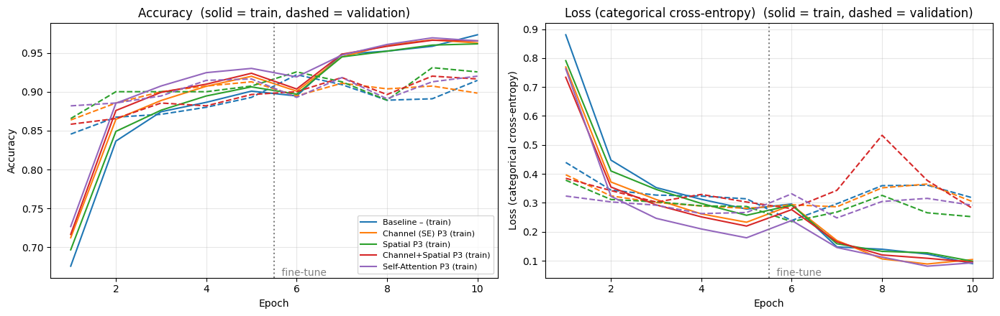

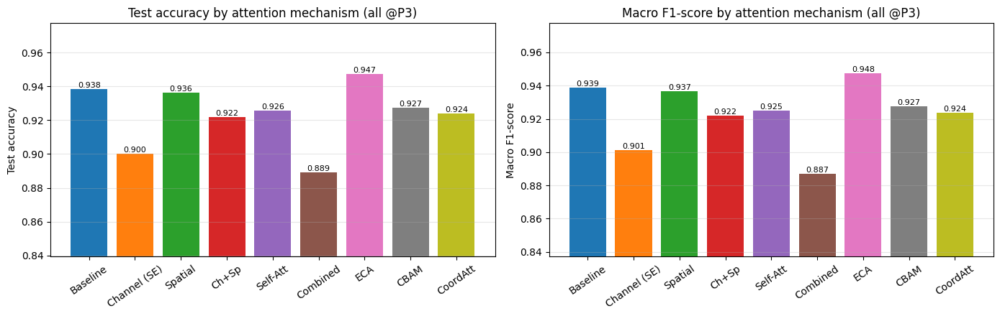

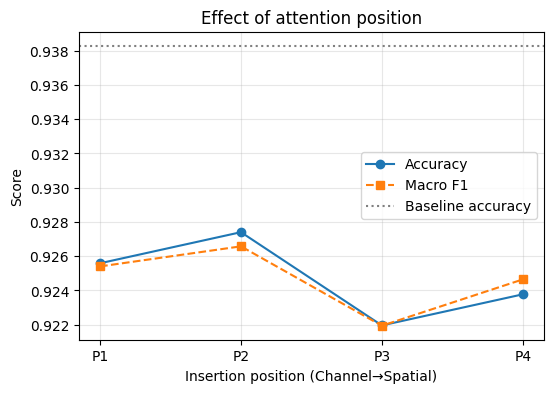

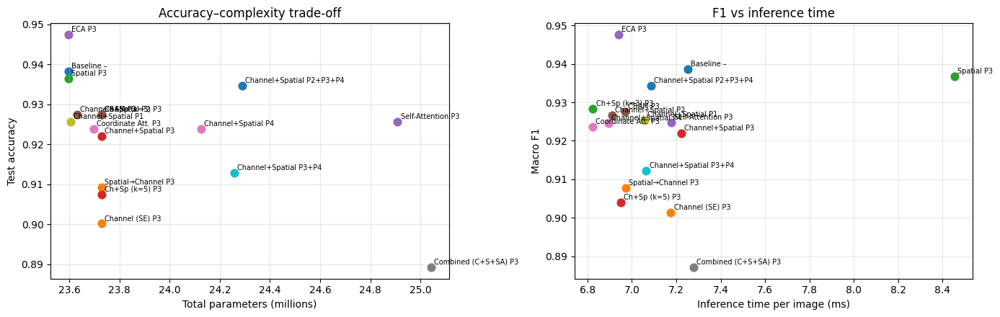

In [ ]:
# 24.1 / 24.2  training & validation accuracy and loss  (required visualisations 2 and 3)
CURVE_MODELS = [n for n in ['A0_baseline','A1_channel_P3','A2_spatial_P3','A3_chan_spatial_P3','A4_selfattn_P3'] if have(n)]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (key, title) in enumerate([('accuracy', 'Accuracy'), ('loss', 'Loss (categorical cross-entropy)')]):
    for j, n in enumerate(CURVE_MODELS):
        h = RES[n]['history']; ep = np.arange(1, len(h[key]) + 1); c = f'C{j}'
        axs[i].plot(ep, h[key], '-', color=c, label=f'{EXPERIMENTS[n]["label"]} {EXPERIMENTS[n]["pos"]} (train)')
        axs[i].plot(ep, h['val_' + key], '--', color=c, label='_nolegend_')
    axs[i].axvline(E1 + 0.5, color='gray', ls=':'); axs[i].text(E1 + 0.6, axs[i].get_ylim()[0], ' fine-tune', color='gray', va='bottom')
    axs[i].set_xlabel('Epoch'); axs[i].set_ylabel(title); axs[i].set_title(title + '  (solid = train, dashed = validation)'); axs[i].grid(alpha=.3)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# 24.3 / 24.4 bar graphs  (required visualisation 14)
bar = [('A0_baseline','Baseline'),('A1_channel_P3','Channel (SE)'),('A2_spatial_P3','Spatial'),('A3_chan_spatial_P3','Ch+Sp'),
       ('A4_selfattn_P3','Self-Att'),('A5_combined_P3','Combined'),('X1_ECA_P3','ECA'),('X2_CBAM_P3','CBAM'),('X3_CoordAtt_P3','CoordAtt')]
bar = [(n, l) for n, l in bar if have(n)]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, key, t in [(axs[0], 'test_acc', 'Test accuracy'), (axs[1], 'f1', 'Macro F1-score')]:
    vals = [RES[n][key] for n, _ in bar]
    b = ax.bar([l for _, l in bar], vals, color=[f'C{i}' for i in range(len(bar))])
    ax.set_ylim(max(0, min(vals) - 0.05), min(1.0, max(vals) + 0.03)); ax.set_ylabel(t); ax.set_title(f'{t} by attention mechanism (all @P3)')
    for r_, v in zip(b, vals): ax.text(r_.get_x() + r_.get_width() / 2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
    ax.tick_params(axis='x', rotation=35); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

# accuracy / F1 versus insertion position (Experiment 2)
pp = [(n, p) for n, p in [('B1_cs_P1','P1'),('B2_cs_P2','P2'),('A3_chan_spatial_P3','P3'),('B4_cs_P4','P4')] if have(n)]
if pp:
    plt.figure(figsize=(6, 4))
    plt.plot([p for _, p in pp], [RES[n]['test_acc'] for n, _ in pp], 'o-', label='Accuracy')
    plt.plot([p for _, p in pp], [RES[n]['f1'] for n, _ in pp], 's--', label='Macro F1')
    if have('A0_baseline'): plt.axhline(RES['A0_baseline']['test_acc'], color='gray', ls=':', label='Baseline accuracy')
    plt.xlabel('Insertion position (Channel→Spatial)'); plt.ylabel('Score'); plt.legend(); plt.grid(alpha=.3)
    plt.title('Effect of attention position'); plt.show()

# 24.5 accuracy vs parameters, 24.6 macro-F1 vs inference time
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
allm = [n for n in RES]
for n in allm:
    lab = EXPERIMENTS[n]['label'] + ' ' + EXPERIMENTS[n]['pos']
    axs[0].scatter(RES[n]['total_params'] / 1e6, RES[n]['test_acc'], s=60); axs[0].annotate(lab, (RES[n]['total_params'] / 1e6, RES[n]['test_acc']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    axs[1].scatter(RES[n]['inference_ms'], RES[n]['f1'], s=60); axs[1].annotate(lab, (RES[n]['inference_ms'], RES[n]['f1']), fontsize=7, xytext=(3, 3), textcoords='offset points')
axs[0].set_xlabel('Total parameters (millions)'); axs[0].set_ylabel('Test accuracy'); axs[0].set_title('Accuracy–complexity trade-off')
axs[1].set_xlabel('Inference time per image (ms)'); axs[1].set_ylabel('Macro F1'); axs[1].set_title('F1 vs inference time')
for a in axs: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

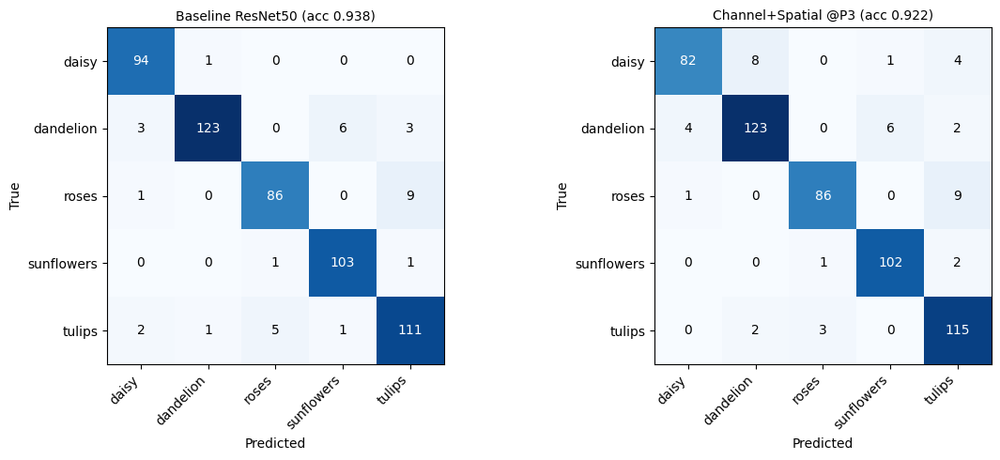

,F1 baseline,F1 attention,change
daisy,0.964,0.901,-0.063
dandelion,0.946,0.918,-0.028
roses,0.915,0.925,+0.010
sunflowers,0.958,0.953,-0.005
tulips,0.910,0.913,+0.003


              precision    recall  f1-score   support

       daisy      0.943     0.863     0.901        95
   dandelion      0.925     0.911     0.918       135
       roses      0.956     0.896     0.925        96
  sunflowers      0.936     0.971     0.953       105
      tulips      0.871     0.958     0.913       120

    accuracy                          0.922       551
   macro avg      0.926     0.920     0.922       551
weighted avg      0.924     0.922     0.922       551



In [ ]:
# Sec. 25  confusion matrices (baseline vs selected attention model) + per-class F1  (required visualisation 4)
def plot_cm(ax, n, title):
    cm = confusion_matrix(yte, RES[n]['y_pred'], labels=range(NUM_CLASSES))
    ax.imshow(cm, cmap='Blues'); ax.set_title(title, fontsize=10)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')

if have('A0_baseline') and have(ATTN_MODEL):
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    plot_cm(axs[0], 'A0_baseline', f'Baseline ResNet50 (acc {RES["A0_baseline"]["test_acc"]:.3f})')
    plot_cm(axs[1], ATTN_MODEL, f'{EXPERIMENTS[ATTN_MODEL]["label"]} @{EXPERIMENTS[ATTN_MODEL]["pos"]} (acc {RES[ATTN_MODEL]["test_acc"]:.3f})')
    plt.tight_layout(); plt.show()
    f_b = precision_recall_fscore_support(yte, RES['A0_baseline']['y_pred'], labels=range(NUM_CLASSES), zero_division=0)[2]
    f_a = precision_recall_fscore_support(yte, RES[ATTN_MODEL]['y_pred'], labels=range(NUM_CLASSES), zero_division=0)[2]
    display(pd.DataFrame({'F1 baseline': f_b, 'F1 attention': f_a, 'change': f_a - f_b}, index=CLASS_NAMES).style.format('{:+.3f}', subset=['change']).format('{:.3f}', subset=['F1 baseline', 'F1 attention']))
    print(classification_report(yte, RES[ATTN_MODEL]['y_pred'], target_names=CLASS_NAMES, digits=3))

## 8. Qualitative analysis (Sec. 26 – 32)
* **Internal attention** = weights the module computes in the forward pass (channel weights, spatial map, self-attention matrix).
* **Grad-CAM** = post-hoc, gradient-based explanation of the class score, taken at the last convolutional feature map (before global average pooling).

Describe what you *see* in the figures (e.g. "stronger activation over petals, weaker over leaves"); avoid saying only "model A is better".

In [ ]:
LOADED = {}
def get_model(name):
    if name not in LOADED:
        cfg = EXPERIMENTS[name]
        m, p = build_model(cfg['attn'], cfg.get('kernel', 7))
        m.load_weights(OUT / 'weights' / f'{name}.weights.h5')
        LOADED[name] = (m, p)
    return LOADED[name]

def to_224(m):
    m = np.asarray(m, dtype='float32')
    if m.ndim == 2: m = m[..., None]
    m = tf.image.resize(m, (224, 224), method='bilinear').numpy()[..., 0]
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

def overlay(img, m, alpha=0.45):
    return np.clip((1 - alpha) * img / 255.0 + alpha * plt.cm.jet(m)[..., :3], 0, 1)

def gradcam(name, imgs, class_idx=None):
    # Grad-CAM (Sec. 27): alpha_k = GAP(d y_c / d A_k);  L = ReLU(sum_k alpha_k A_k)
    _, parts = get_model(name)
    x = tf.constant(imgs, dtype=tf.float32)
    with tf.GradientTape() as tape:
        feat, logits, probs = parts['cam_model'](x, training=False)
        cls = tf.argmax(logits, axis=1) if class_idx is None else tf.constant(class_idx, dtype=tf.int64)
        score = tf.gather(logits, cls, axis=1, batch_dims=1)
    grads = tape.gradient(score, feat)
    alpha = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(alpha * feat, axis=-1)).numpy()
    return np.stack([to_224(c) for c in cam]), probs.numpy().argmax(1)

def explain(name, imgs):
    # internal attention: pre/post feature maps and the module's own attention weights at each position
    _, parts = get_model(name)
    feats = parts['probe'](tf.constant(imgs, dtype=tf.float32), training=False)
    out = {}
    for pos, blk in parts['blocks'].items():
        pre = feats[pos - 1]; post, maps = blk.explain(pre)
        out[pos] = dict(pre=pre.numpy(), post=post.numpy(), maps={k: v.numpy() for k, v in maps.items()})
    return out

# representative test images: 3 correct (different classes) + 2 incorrect for the selected attention model
pa = np.array(RES[ATTN_MODEL]['y_pred']) if have(ATTN_MODEL) else np.array(RES['A0_baseline']['y_pred'])
correct, seen = [], set()
for i in np.where(pa == yte)[0]:
    if yte[i] not in seen: correct.append(int(i)); seen.add(yte[i])
    if len(correct) == 3: break
wrong = [int(i) for i in np.where(pa != yte)[0][:2]]
REP = correct + wrong
print('correct:', correct, '| incorrect:', wrong)
print('true labels:', [CLASS_NAMES[yte[i]] for i in REP], '| predicted:', [CLASS_NAMES[pa[i]] for i in REP])

correct: [0, 1, 3] | incorrect: [14, 21]
true labels: ['roses', 'daisy', 'tulips', 'daisy', 'daisy'] | predicted: ['roses', 'daisy', 'tulips', 'dandelion', 'dandelion']


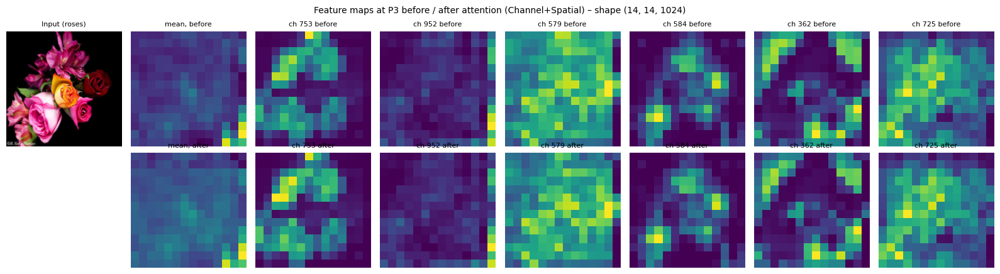

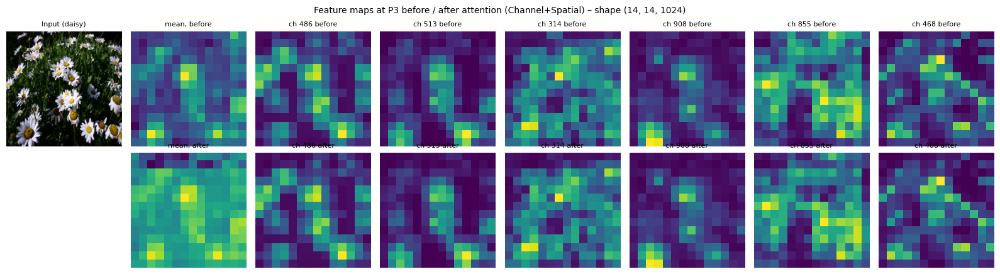

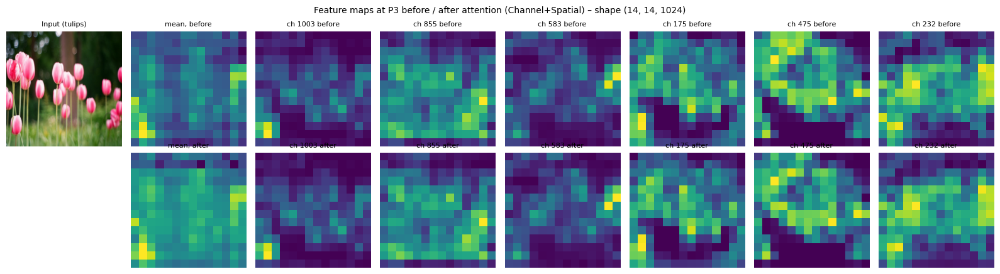

In [ ]:
# Required visualisations 5 & 10: feature map BEFORE and AFTER attention (selected model, position P3)
if have(ATTN_MODEL):
    pos = max(EXPERIMENTS[ATTN_MODEL]['attn'].keys()); idxs = REP[:3]
    ex = explain(ATTN_MODEL, Xte[idxs])[pos]
    K = 6
    for r_, i in enumerate(idxs):
        pre, post = ex['pre'][r_], ex['post'][r_]
        top = np.argsort(pre.mean(axis=(0, 1)))[::-1][:K]                  # same channels before and after
        fig, axs = plt.subplots(2, K + 2, figsize=(2 * (K + 2), 4.4))
        axs[0, 0].imshow(Xte[i]); axs[0, 0].set_title(f'Input ({CLASS_NAMES[yte[i]]})', fontsize=8); axs[1, 0].axis('off')
        axs[0, 1].imshow(pre.mean(-1), cmap='viridis'); axs[0, 1].set_title('mean, before', fontsize=8)
        axs[1, 1].imshow(post.mean(-1), cmap='viridis'); axs[1, 1].set_title('mean, after', fontsize=8)
        for j, c in enumerate(top):
            axs[0, j + 2].imshow(pre[..., c], cmap='viridis'); axs[0, j + 2].set_title(f'ch {c} before', fontsize=8)
            axs[1, j + 2].imshow(post[..., c], cmap='viridis'); axs[1, j + 2].set_title(f'ch {c} after', fontsize=8)
        for a in axs.ravel(): a.axis('off')
        plt.suptitle(f'Feature maps at P{pos} before / after attention ({EXPERIMENTS[ATTN_MODEL]["label"]}) – shape {pre.shape}', fontsize=10)
        plt.tight_layout(); plt.show()

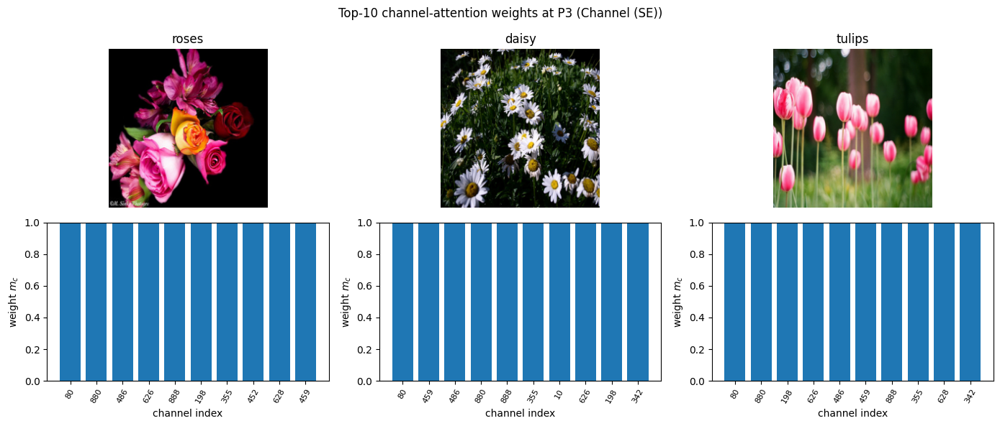

Weight statistics (C = 1024):
  image 0: mean 0.711, std 0.409, min 0.002, max 1.000, top-10 channels hold 1.4% of total weight
  image 1: mean 0.710, std 0.410, min 0.002, max 1.000, top-10 channels hold 1.4% of total weight
  image 2: mean 0.712, std 0.408, min 0.002, max 1.000, top-10 channels hold 1.4% of total weight
  overlap of top-10 channels: img0∩img1 = 8, img0∩img2 = 9, img1∩img2 = 9


In [ ]:
# Required visualisation 6: channel-attention weights, top-K channels (Sec. 28.1)
K = 10
name = 'A1_channel_P3' if have('A1_channel_P3') else ATTN_MODEL
if have(name):
    idxs = REP[:3]; ex = explain(name, Xte[idxs]); pos = list(ex.keys())[0]; w = ex[pos]['maps']['c']     # (B, C)
    fig, axs = plt.subplots(2, 3, figsize=(14, 6))
    tops = []
    for j, i in enumerate(idxs):
        top = np.argsort(w[j])[::-1][:K]; tops.append(set(top))
        axs[0, j].imshow(Xte[i]); axs[0, j].axis('off'); axs[0, j].set_title(f'{CLASS_NAMES[yte[i]]}')
        axs[1, j].bar(range(K), w[j][top]); axs[1, j].set_xticks(range(K)); axs[1, j].set_xticklabels(top, rotation=60, fontsize=8)
        axs[1, j].set_ylim(0, 1); axs[1, j].set_xlabel('channel index'); axs[1, j].set_ylabel('weight $m_c$')
    plt.suptitle(f'Top-{K} channel-attention weights at P{pos} ({EXPERIMENTS[name]["label"]})'); plt.tight_layout(); plt.show()
    print(f'Weight statistics (C = {w.shape[1]}):')
    for j, i in enumerate(idxs):
        print(f'  image {j}: mean {w[j].mean():.3f}, std {w[j].std():.3f}, min {w[j].min():.3f}, max {w[j].max():.3f}, '
              f'top-{K} channels hold {np.sort(w[j])[::-1][:K].sum() / w[j].sum() * 100:.1f}% of total weight')
    print(f'  overlap of top-{K} channels: img0∩img1 = {len(tops[0] & tops[1])}, img0∩img2 = {len(tops[0] & tops[2])}, img1∩img2 = {len(tops[1] & tops[2])}')

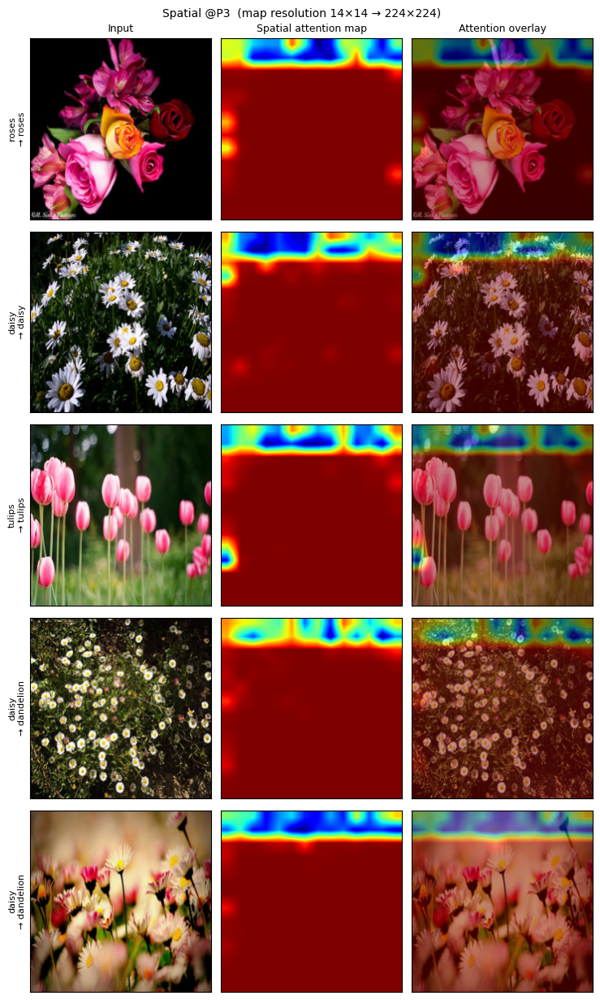

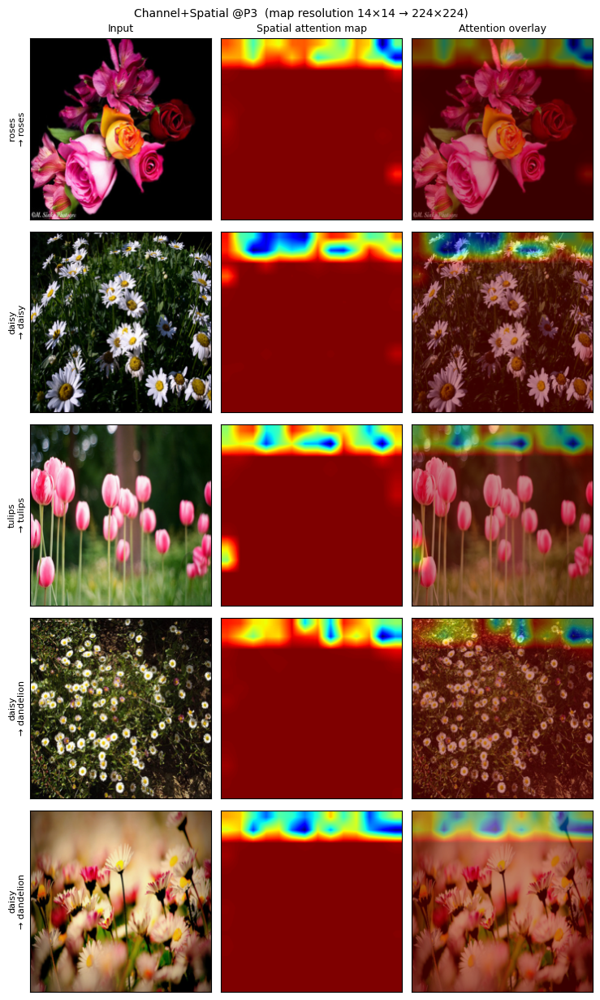

In [ ]:
# Required visualisations 7 & 8: spatial-attention heatmap and overlay (Sec. 28.2)
for name in ['A2_spatial_P3', ATTN_MODEL]:
    if not have(name): continue
    ex = explain(name, Xte[REP]); pos = list(ex.keys())[0]; ms = ex[pos]['maps']['s']
    fig, axs = plt.subplots(len(REP), 3, figsize=(7.5, 2.5 * len(REP)))
    for r_, i in enumerate(REP):
        m = to_224(ms[r_])
        axs[r_, 0].imshow(Xte[i]); axs[r_, 1].imshow(m, cmap='jet'); axs[r_, 2].imshow(overlay(Xte[i], m))
        axs[r_, 0].set_ylabel(f'{CLASS_NAMES[yte[i]]}\n→ {CLASS_NAMES[pa[i]]}', fontsize=8)
        for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
    for a, t in zip(axs[0], ['Input', 'Spatial attention map', 'Attention overlay']): a.set_title(t, fontsize=9)
    plt.suptitle(f'{EXPERIMENTS[name]["label"]} @P{pos}  (map resolution {ms.shape[1]}×{ms.shape[2]} → 224×224)', fontsize=10)
    plt.tight_layout(); plt.show()

A4_selfattn_P3: learned residual scale gamma = -0.02632996439933777


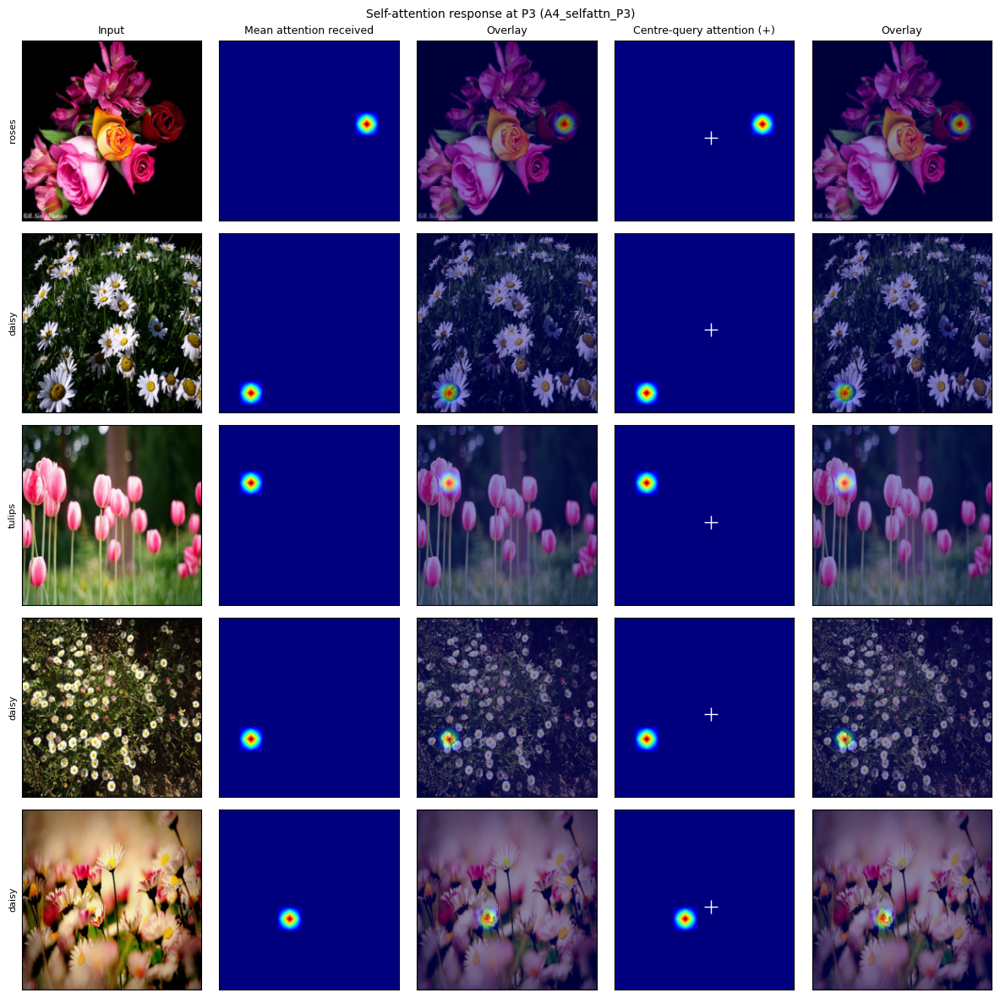

A5_combined_P3: learned residual scale gamma = -0.022876420989632607


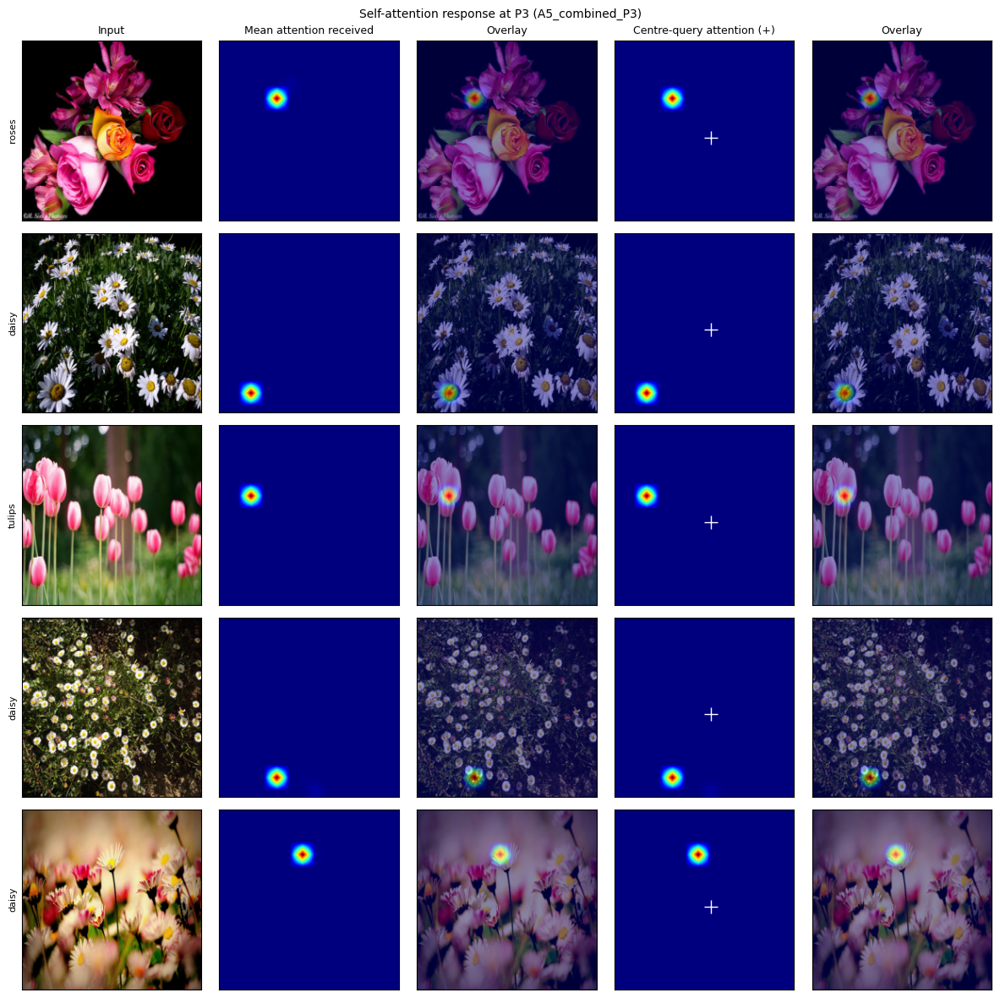

In [ ]:
# Required visualisation 9: self-attention response (Sec. 28.3)
for name in ['A4_selfattn_P3', 'A5_combined_P3']:
    if not have(name): continue
    ex = explain(name, Xte[REP]); pos = list(ex.keys())[0]; m = ex[pos]['maps']['sa']              # (B,H,W,2)
    print(f'{name}: learned residual scale gamma =', float(get_model(name)[1]['blocks'][pos].mods[-1].gamma.numpy()))
    fig, axs = plt.subplots(len(REP), 5, figsize=(12, 2.4 * len(REP)))
    for r_, i in enumerate(REP):
        mean_m, cen_m = to_224(m[r_, ..., 0]), to_224(m[r_, ..., 1])
        axs[r_, 0].imshow(Xte[i]); axs[r_, 1].imshow(mean_m, cmap='jet'); axs[r_, 2].imshow(overlay(Xte[i], mean_m))
        axs[r_, 3].imshow(cen_m, cmap='jet'); axs[r_, 4].imshow(overlay(Xte[i], cen_m))
        H = m.shape[1]; c = (H // 2) * 224 / H + 224 / H / 2
        axs[r_, 3].plot(c, c, 'w+', ms=12); axs[r_, 0].set_ylabel(f'{CLASS_NAMES[yte[i]]}', fontsize=8)
        for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
    for a, t in zip(axs[0], ['Input', 'Mean attention received', 'Overlay', 'Centre-query attention (+)', 'Overlay']): a.set_title(t, fontsize=9)
    plt.suptitle(f'Self-attention response at P{pos} ({name})', fontsize=10); plt.tight_layout(); plt.show()

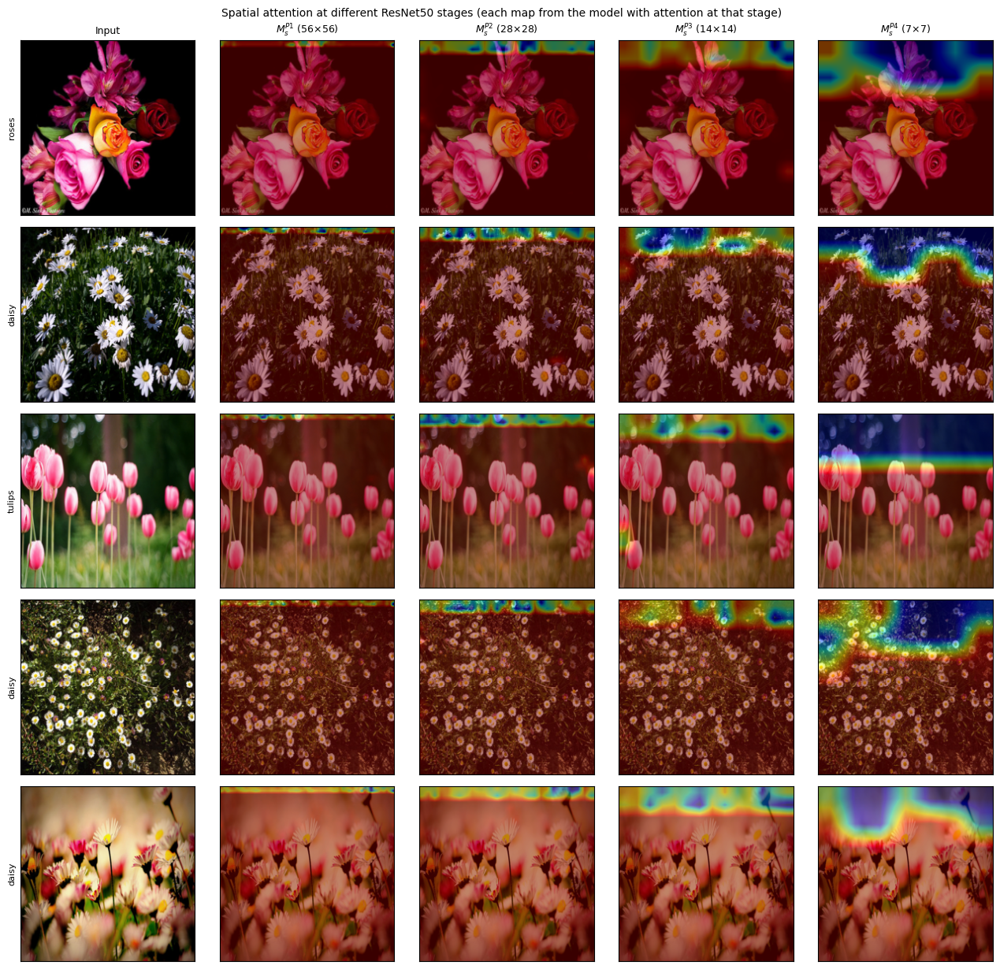

In [ ]:
# Required visualisation 13: spatial attention at P2, P3, P4 for the same test images (Sec. 29)
pos_models = [(p, n) for p, n in [(1, 'B1_cs_P1'), (2, 'B2_cs_P2'), (3, 'A3_chan_spatial_P3'), (4, 'B4_cs_P4')] if have(n)]
if pos_models:
    maps_by_pos = {p: explain(n, Xte[REP])[p]['maps']['s'] for p, n in pos_models}
    fig, axs = plt.subplots(len(REP), 1 + len(pos_models), figsize=(2.6 * (1 + len(pos_models)), 2.5 * len(REP)))
    for r_, i in enumerate(REP):
        axs[r_, 0].imshow(Xte[i]); axs[r_, 0].set_ylabel(CLASS_NAMES[yte[i]], fontsize=8)
        for j, (p, _) in enumerate(pos_models):
            axs[r_, j + 1].imshow(overlay(Xte[i], to_224(maps_by_pos[p][r_])))
        for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
    axs[0, 0].set_title('Input', fontsize=9)
    for j, (p, _) in enumerate(pos_models):
        h = maps_by_pos[p].shape[1]; axs[0, j + 1].set_title(f'$M_s^{{P{p}}}$ ({h}×{h})', fontsize=9)
    plt.suptitle('Spatial attention at different ResNet50 stages (each map from the model with attention at that stage)', fontsize=10)
    plt.tight_layout(); plt.show()

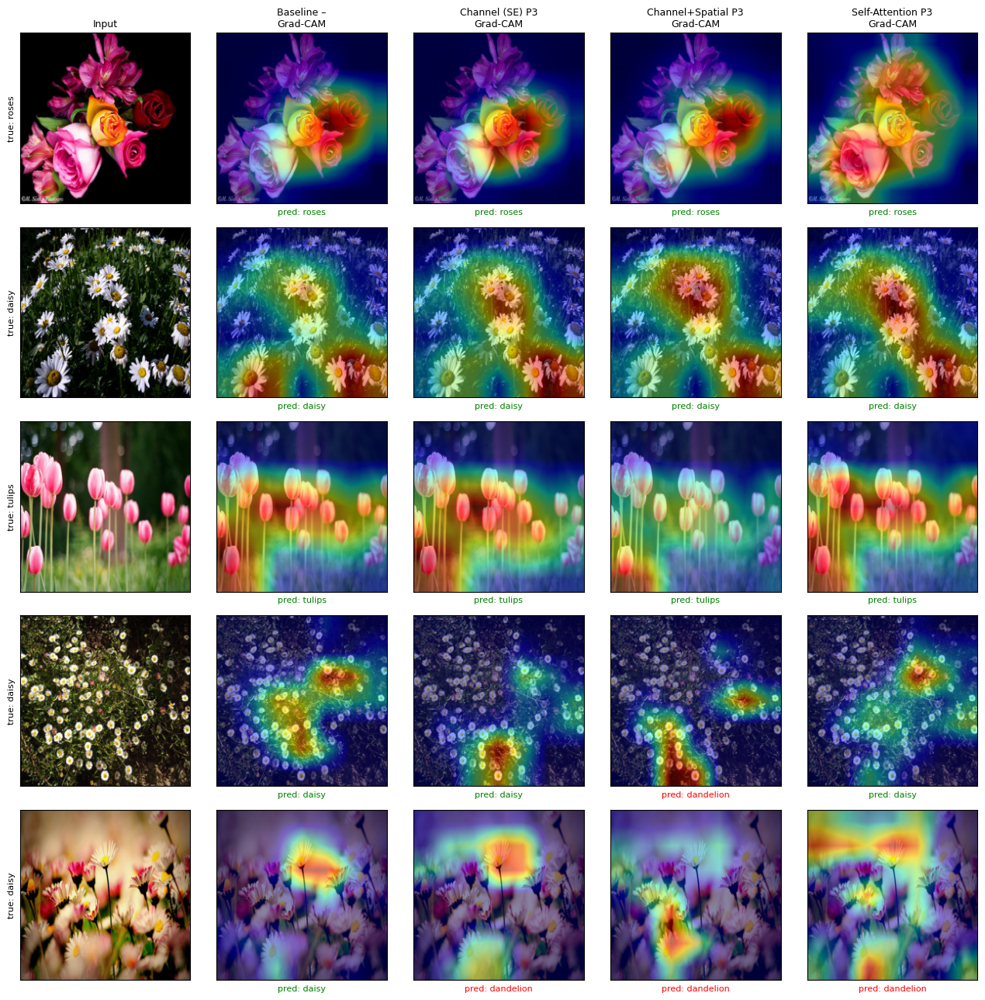

Grad-CAM statistics per image: (coverage CAM>0.5 | mass in central window)
  Baseline –                   (0.17|0.52) (0.33|0.31) (0.41|0.38) (0.14|0.57) (0.06|0.55)
  Channel (SE) P3              (0.16|0.60) (0.35|0.37) (0.41|0.39) (0.06|0.29) (0.10|0.33)
  Channel+Spatial P3           (0.17|0.48) (0.36|0.37) (0.18|0.35) (0.10|0.28) (0.07|0.36)
  Self-Attention P3            (0.37|0.41) (0.36|0.38) (0.43|0.37) (0.04|0.48) (0.19|0.27)


In [ ]:
# Required visualisations 11 & 12: Grad-CAM, baseline vs attention models (Sec. 27, 32)
show = [(n, EXPERIMENTS[n]['label'] + ' ' + EXPERIMENTS[n]['pos']) for n in
        ['A0_baseline', 'A1_channel_P3', 'A3_chan_spatial_P3', 'A4_selfattn_P3'] if have(n)]
cams = {n: gradcam(n, Xte[REP]) for n, _ in show}
fig, axs = plt.subplots(len(REP), 1 + len(show), figsize=(2.6 * (1 + len(show)), 2.6 * len(REP)))
for r_, i in enumerate(REP):
    axs[r_, 0].imshow(Xte[i]); axs[r_, 0].set_ylabel(f'true: {CLASS_NAMES[yte[i]]}', fontsize=8)
    for j, (n, lab) in enumerate(show):
        cam, pr = cams[n]; axs[r_, j + 1].imshow(overlay(Xte[i], cam[r_]))
        axs[r_, j + 1].set_xlabel(f'pred: {CLASS_NAMES[pr[r_]]}', fontsize=8, color='green' if pr[r_] == yte[i] else 'red')
    for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_title('Input', fontsize=9)
for j, (_, lab) in enumerate(show): axs[0, j + 1].set_title(lab + '\nGrad-CAM', fontsize=9)
plt.tight_layout(); plt.show()

# Simple numeric support for the visual claims: how much Grad-CAM mass lies in the central region, and compactness
def cam_stats(c):
    thr = (c > 0.5).mean()                                                  # fraction of image with CAM > 0.5
    cy, cx = np.mgrid[0:224, 0:224]; w = c / (c.sum() + 1e-8)
    return thr, float(w[(abs(cy - 112) < 56) & (abs(cx - 112) < 56)].sum()) # mass in central 112x112 window
print('Grad-CAM statistics per image: (coverage CAM>0.5 | mass in central window)')
for j, (n, lab) in enumerate(show):
    print(f'  {lab:28s}', ' '.join(f'({cam_stats(cams[n][0][r_])[0]:.2f}|{cam_stats(cams[n][0][r_])[1]:.2f})' for r_ in range(len(REP))))

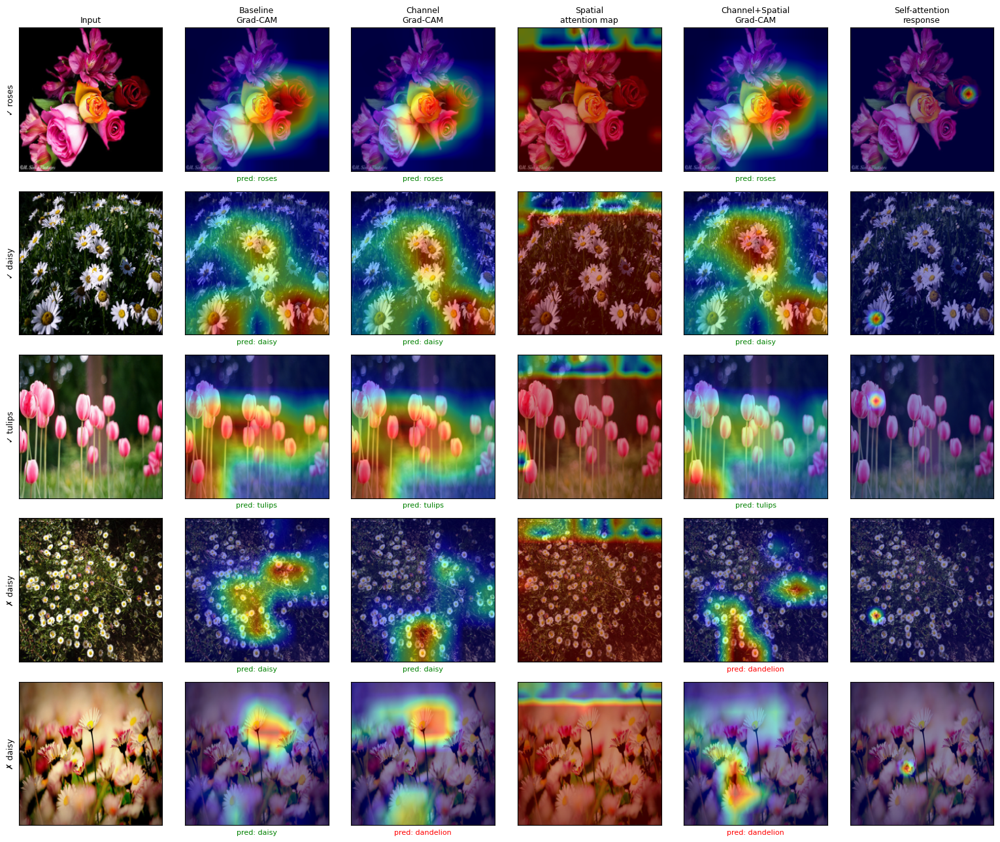

In [ ]:
# Sec. 30: qualitative comparison across mechanisms - 3 correct + 2 incorrect images
cols = [('A0_baseline', 'cam', 'Baseline\nGrad-CAM'), ('A1_channel_P3', 'cam', 'Channel\nGrad-CAM'),
        ('A2_spatial_P3', 'attn_s', 'Spatial\nattention map'), ('A3_chan_spatial_P3', 'cam', 'Channel+Spatial\nGrad-CAM'),
        ('A4_selfattn_P3', 'attn_sa', 'Self-attention\nresponse')]
cols = [c for c in cols if have(c[0])]
fig, axs = plt.subplots(len(REP), 1 + len(cols), figsize=(2.6 * (1 + len(cols)), 2.6 * len(REP)))
for j, (n, kind, t) in enumerate(cols):
    if kind == 'cam':
        cam, pr = gradcam(n, Xte[REP]); ims = [overlay(Xte[i], cam[r_]) for r_, i in enumerate(REP)]; ok = pr
    else:
        ex = explain(n, Xte[REP]); pos = list(ex.keys())[0]
        mm = ex[pos]['maps']['s'] if kind == 'attn_s' else ex[pos]['maps']['sa'][..., 0]
        ims = [overlay(Xte[i], to_224(mm[r_])) for r_, i in enumerate(REP)]; ok = None
    for r_ in range(len(REP)):
        axs[r_, j + 1].imshow(ims[r_])
        if ok is not None: axs[r_, j + 1].set_xlabel(f'pred: {CLASS_NAMES[ok[r_]]}', fontsize=8, color='green' if ok[r_] == yte[REP[r_]] else 'red')
    axs[0, j + 1].set_title(t, fontsize=9)
for r_, i in enumerate(REP):
    axs[r_, 0].imshow(Xte[i]); axs[r_, 0].set_ylabel(('✓ ' if r_ < len(correct) else '✗ ') + CLASS_NAMES[yte[i]], fontsize=9)
    for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_title('Input', fontsize=9); plt.tight_layout(); plt.show()

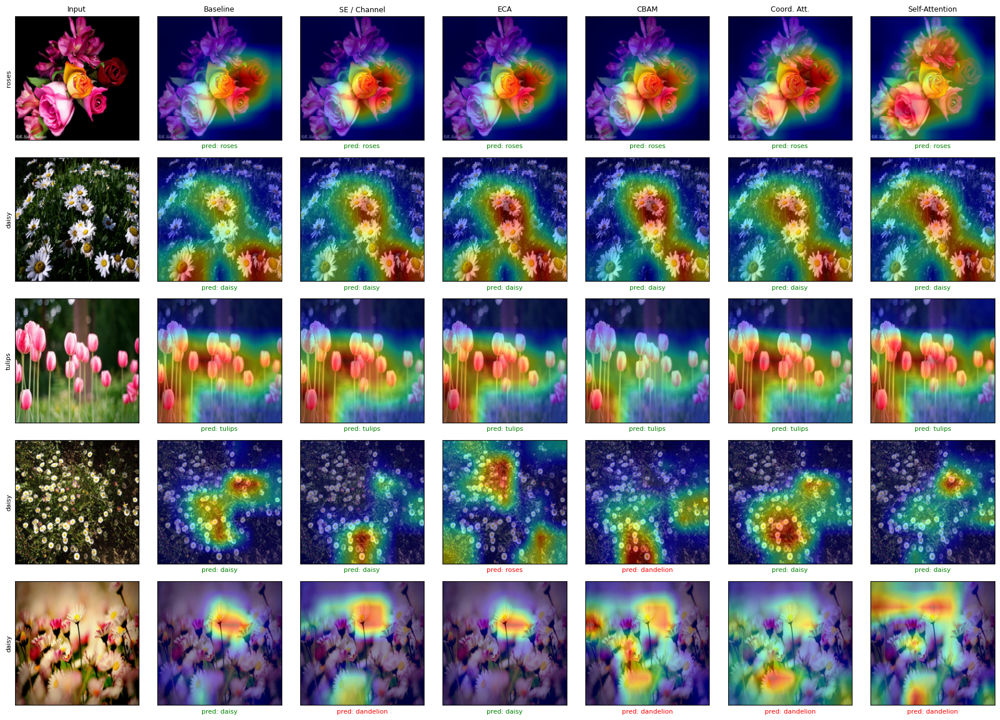

In [ ]:
# Sec. 32: extended figure  Input | Baseline | SE | ECA | CBAM | Self-Attention  (Grad-CAM for every model)
ext = [(n, l) for n, l in [('A0_baseline', 'Baseline'), ('A1_channel_P3', 'SE / Channel'), ('X1_ECA_P3', 'ECA'),
                           ('X2_CBAM_P3', 'CBAM'), ('X3_CoordAtt_P3', 'Coord. Att.'), ('A4_selfattn_P3', 'Self-Attention')] if have(n)]
if len(ext) > 2:
    fig, axs = plt.subplots(len(REP), 1 + len(ext), figsize=(2.5 * (1 + len(ext)), 2.5 * len(REP)))
    allcams = {n: gradcam(n, Xte[REP]) for n, _ in ext}
    for r_, i in enumerate(REP):
        axs[r_, 0].imshow(Xte[i]); axs[r_, 0].set_ylabel(CLASS_NAMES[yte[i]], fontsize=8)
        for j, (n, l) in enumerate(ext):
            axs[r_, j + 1].imshow(overlay(Xte[i], allcams[n][0][r_]))
            axs[r_, j + 1].set_xlabel(f'pred: {CLASS_NAMES[allcams[n][1][r_]]}', fontsize=8, color='green' if allcams[n][1][r_] == yte[i] else 'red')
        for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
    axs[0, 0].set_title('Input', fontsize=9)
    for j, (n, l) in enumerate(ext): axs[0, j + 1].set_title(l, fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print('Train the `extra` tier (ECA, CBAM, Coordinate Attention) to enable this figure.')

## 9. Discussion template (Sec. 37 – 41)
Answer from **your own numbers and figures** (several images, not one). Suggested structure for the report: Aim · Dataset · ResNet50 · Attention mechanisms · Architecture · Setup · Type ablation · Position ablation · Results · Complexity · Curves · Confusion matrix · Grad-CAM · Internal attention maps · Qualitative comparison · Additional mechanisms · Discussion · Conclusion.

**Discussion prompts (Sec. 40)** – write 2–4 sentences each, citing a table row or a figure:
* Why did each attention type change (or not change) accuracy / macro-F1 at P3?
* How did the position (P1/P2/P3/P4) affect performance, and how does resolution/semantics explain it?
* Did multiple positions (P3+P4, P2+P3+P4) justify the extra parameters and inference time?
* Channel→Spatial vs Spatial→Channel; effect of kernel size 3/5/7.
* Do the attention maps lie on the flower? Is the background suppressed? Do wrong predictions look different?
* Do the quantitative and qualitative observations agree? Which classes benefit (confusion matrix)?

**Question bank (Sec. 37)** – conceptual: 1 residual connections · 2 conv2_x vs conv5_x · 3 resolution↓ with depth · 4 channels↑ with depth · 5 low/mid/high-level features · 6–10 purpose of attention, channel vs spatial, why sequential · 11 channel attention at conv3_x vs conv5_x · 12 spatial attention at mid stage · 13–14 cost of self-attention and size of the N×N matrix (N = H·W: P2 = 784, P3 = 196, P4 = 49) · 20–22 SE vs ECA, CBAM, self- vs channel attention · 24–25 internal attention vs Grad-CAM (post-hoc) · 29–32 confusion matrix, macro-F1, accuracy–complexity and F1–time trade-offs · 33–34 why identical split / protocol.
Experimental: 15–19, 23, 26–28, 35 – answer using the results above.

In [ ]:
# Package everything for the report / submission
zpath = '/content/attention_lab_outputs.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in OUT.glob('*.json'): z.write(p, p.name)
    for p in OUT.glob('*.csv'): z.write(p, p.name)
    for p in OUT.glob('*.npz'): z.write(p, p.name)
print('Saved', zpath, '(results JSON/CSV + split indices; weights stay in', OUT / 'weights', ')')
try:
    from google.colab import files; files.download(zpath)
except Exception as e:
    print('Download manually from the Files panel:', e)

Saved /content/attention_lab_outputs.zip (results JSON/CSV + split indices; weights stay in /content/lab_outputs/weights )


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>